In [ ]:
import json
import os
import subprocess
import urllib.request
import zipfile
import tarfile

os.makedirs("/content/RUOD_raw", exist_ok=True)
os.chdir("/content/RUOD_raw")

# Clean up any leftover HTML/corrupt files from earlier runs
for fname in os.listdir("."):
    if fname.lower().startswith("ruod"):
        os.remove(fname)

# Build API endpoint without a literal URL so copy-paste cannot strip the path
api_endpoint = "".join([
    "https", "://", "api.", "figshare.", "com",
    "/v2/articles/32306172"
])

print("Fetching official RUOD file metadata from Figshare API...")
req = urllib.request.Request(api_endpoint, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    article_data = json.loads(resp.read().decode("utf-8"))

files = article_data.get("files", [])
if not files:
    raise RuntimeError("No files returned from Figshare article 32306172.")

# Pick the main dataset archive (largest file, ~3.3 GB)
target_file = max(files, key=lambda f: f.get("size", 0))
file_name = target_file["name"]
download_url = target_file["download_url"]
size_gb = target_file["size"] / (1024 ** 3)

print(f"Downloading {file_name} ({size_gb:.2f} GB)...")
subprocess.run(["wget", "-q", "--show-progress", "-O", file_name, download_url], check=True)

print(f"Extracting {file_name}...")
if file_name.endswith(".zip"):
    with zipfile.ZipFile(file_name, "r") as zf:
        zf.extractall("/content/RUOD_raw")
elif ".tar" in file_name:
    with tarfile.open(file_name, "r:*") as tf:
        tf.extractall("/content/RUOD_raw")

os.remove(file_name)

print("\nExtraction complete! Directory contents:")
for root, dirs, files_list in os.walk("/content/RUOD_raw"):
    level = root.replace("/content/RUOD_raw", "").count(os.sep)
    if level <= 2:
        print(f"{'  ' * level}{os.path.basename(root)}/ ({len(files_list)} files)")


Fetching official RUOD file metadata from Figshare API...
Extracting ruod.zip...

Extraction complete! Directory contents:
RUOD_raw/ (0 files)
  ruod/ (0 files)
    images/ (0 files)
    labels/ (2 files)


In [ ]:
from pathlib import Path
import os

RAW_ROOT = Path("/content/RUOD_raw")

print("Does dataset directory exist?", RAW_ROOT.exists())

print("\nAll JSON files:")
for f in RAW_ROOT.rglob("*.json"):
    print(f)

print("\nAll directories:")
for p in RAW_ROOT.rglob("*"):
    if p.is_dir():
        print(p)

print("\nImage files:")
count = 0
for ext in ["*.jpg", "*.jpeg", "*.png"]:
    for f in RAW_ROOT.rglob(ext):
        print(f)
        count += 1
        if count >= 20:
            break
    if count >= 20:
        break

print("\nTotal sample images displayed:", count)

Does dataset directory exist? True

All JSON files:

All directories:
/content/RUOD_raw/ruod
/content/RUOD_raw/ruod/images
/content/RUOD_raw/ruod/labels
/content/RUOD_raw/ruod/images/val
/content/RUOD_raw/ruod/images/train
/content/RUOD_raw/ruod/labels/val
/content/RUOD_raw/ruod/labels/train

Image files:
/content/RUOD_raw/ruod/images/val/010685.jpg
/content/RUOD_raw/ruod/images/val/002005.jpg
/content/RUOD_raw/ruod/images/val/011131.jpg
/content/RUOD_raw/ruod/images/val/004716.jpg
/content/RUOD_raw/ruod/images/val/008688.jpg
/content/RUOD_raw/ruod/images/val/013657.jpg
/content/RUOD_raw/ruod/images/val/012848.jpg
/content/RUOD_raw/ruod/images/val/005081.jpg
/content/RUOD_raw/ruod/images/val/009378.jpg
/content/RUOD_raw/ruod/images/val/010383.jpg
/content/RUOD_raw/ruod/images/val/003614.jpg
/content/RUOD_raw/ruod/images/val/013449.jpg
/content/RUOD_raw/ruod/images/val/001013.jpg
/content/RUOD_raw/ruod/images/val/008526.jpg
/content/RUOD_raw/ruod/images/val/001679.jpg
/content/RUOD_raw/

In [ ]:

import os
import yaml
from pathlib import Path

# Dataset paths
RAW_ROOT = Path("/content/RUOD_raw/ruod")
OUTPUT_DIR = Path("/content/RUOD_yolo")

CLASSES = [
    "holothurian",
    "echinus",
    "scallop",
    "starfish",
    "fish",
    "corals",
    "diver",
    "cuttlefish",
    "turtle",
    "jellyfish"
]

# Check dataset directories
for split in ["train", "val"]:
    img_dir = RAW_ROOT / "images" / split
    lbl_dir = RAW_ROOT / "labels" / split

    if not img_dir.exists():
        raise FileNotFoundError(f"Missing image directory: {img_dir}")

    if not lbl_dir.exists():
        raise FileNotFoundError(f"Missing label directory: {lbl_dir}")

# Create output directory
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Create YOLO directory structure using symlinks
for split in ["train", "val"]:
    for category in ["images", "labels"]:

        src = RAW_ROOT / category / split
        dst = OUTPUT_DIR / category / split

        dst.mkdir(parents=True, exist_ok=True)

        for file in src.iterdir():
            if file.is_file():
                target = dst / file.name

                if target.is_symlink() or target.exists():
                    target.unlink()

                os.symlink(file.resolve(), target)

# Count dataset files
for split in ["train", "val"]:
    img_dir = OUTPUT_DIR / "images" / split
    lbl_dir = OUTPUT_DIR / "labels" / split

    print(f"\n{split.upper()}")
    print("Images:", len(list(img_dir.glob("*.jpg"))))
    print("Labels:", len(list(lbl_dir.glob("*.txt"))))

# Generate YAML configuration
yaml_cfg = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        i: name for i, name in enumerate(CLASSES)
    },
    "nc": len(CLASSES)
}

yaml_path = OUTPUT_DIR / "ruod.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(yaml_cfg, f, sort_keys=False)

print("\nDataset preparation complete!")
print("YOLO configuration:", yaml_path)



TRAIN
Images: 9800
Labels: 9800

VAL
Images: 4200
Labels: 4200

Dataset preparation complete!
YOLO configuration: /content/RUOD_yolo/ruod.yaml


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
'''
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/content/RUOD_yolo/ruod.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/RUOD_results",
    name="RUOD_YOLOv8"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/RUOD_yolo/ruod.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

Exception in thread Thread-23 (_pin_memory_loop):


KeyboardInterrupt: 

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 120, in get
    return _ForkingPickler.loads(res)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/multiprocessing/reductions.py", line 538, in rebuild_storage_fd
    fd = df.detach()
  File "/usr/lib/python3.13/multiprocessing/resource_sharer.py", line 57, in detach
    with _resourc

In [ ]:

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/content/RUOD_yolo/ruod.yaml",

    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,

    # Explicit optimization settings
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    warmup_epochs=5,
    weight_decay=0.0005,

    # Training configuration
    patience=20,
    seed=42,
    deterministic=True,

    project="/content/RUOD_results",
    name="RUOD_YOLOv8_AdamW",
    exist_ok=True
)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/RUOD_yolo/ruod.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=RUOD_YOLOv8_AdamW, nbs=64, nms=None, opset=None, optimize=F

In [ ]:
from ultralytics import YOLO

# Load best trained model
model = YOLO(
    "/content/RUOD_results/RUOD_YOLOv8_AdamW/weights/best.pt"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
from pathlib import Path

VAL_DIR = Path("/content/RUOD_yolo/images/val")
PRED_DIR = "/content/RUOD_predictions"

results = model.predict(
    source=str(VAL_DIR),
    imgsz=640,
    conf=0.25,
    iou=0.45,
    save=True,
    save_txt=True,
    save_conf=True,
    project=PRED_DIR,
    name="validation",
    exist_ok=True
)

print("Validation predictions completed!")
print("Results saved at:", f"{PRED_DIR}/validation")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/4200 /content/RUOD_yolo/images/val/000003.jpg: 384x640 1 holothurian, 7.4ms
image 2/4200 /content/RUOD_yolo/images/val/000004.jpg: 384x640 5 holothurians, 1 echinus, 10.1ms
image 3/4200 /content/RUOD_yolo/images/val/000006.jpg: 384x640 1 holothurian, 1 echinus, 1 starfish, 8.1ms
image 4/4200 /content/RUOD_yolo/images/val/000011.jpg: 384x640 1 holothurian, 7.7ms
image 5/4200 /content/RUOD_yolo/images/val/000015.jpg: 384x640 2 starfishs, 6.6ms
image

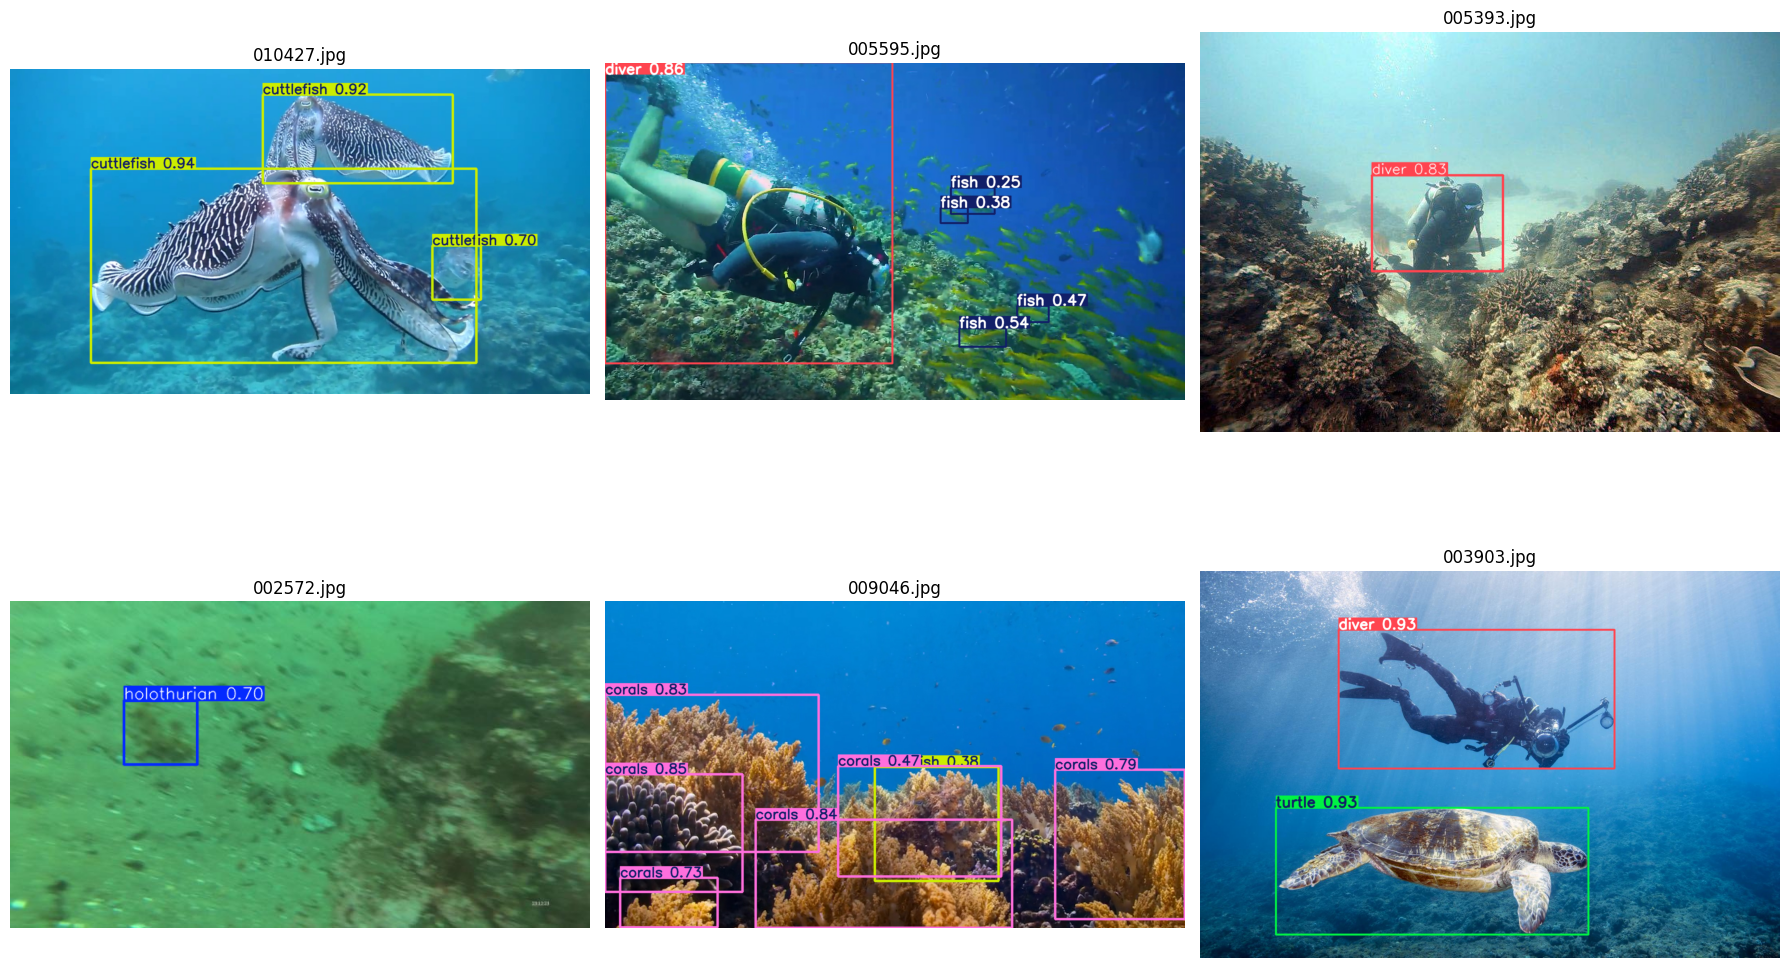

In [ ]:
import random
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

VAL_DIR = Path("/content/RUOD_yolo/images/val")

image_files = list(VAL_DIR.glob("*.jpg"))

# Select 6 random images
sample_images = random.sample(
    image_files,
    min(6, len(image_files))
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, img_path in enumerate(sample_images):

    # YOLO prediction
    result = model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    # Draw bounding boxes
    annotated_img = result.plot()

    # Convert BGR to RGB
    annotated_img = cv2.cvtColor(
        annotated_img,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(annotated_img)
    axes[i].set_title(img_path.name)
    axes[i].axis("off")

# Hide unused plots
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
metrics = model.val(
    data="/content/RUOD_yolo/ruod.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0
)

print("\nValidation Performance")
print("----------------------")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2623.6±1613.5 MB/s, size: 130.6 KB)
val: Scanning /content/RUOD_yolo/labels/val.cache... 4200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4200/4200 978.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 263/263 9.0it/s 29.1s
                   all       4200      22380      0.841      0.772      0.839      0.597
           holothurian        752       2269      0.851      0.676      0.787      0.472
               echinus        775       3306      0.868      0.827      0.887      0.511
               scallop        439       2192      0.823      0.594      0.741       0.45
              starfish        758       2336      0.866      0.799      0.886      0.535
                  fish        959      

In [ ]:
from collections import Counter

class_counts = Counter()

for result in results:
    for cls_id in result.boxes.cls.cpu().numpy():
        class_name = model.names[int(cls_id)]
        class_counts[class_name] += 1

print("Detected objects by class:\n")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Detected objects by class:

holothurian: 2072
echinus: 3489
starfish: 2460
scallop: 2025
cuttlefish: 1727
jellyfish: 862
fish: 4137
corals: 2819
turtle: 1184
diver: 1862


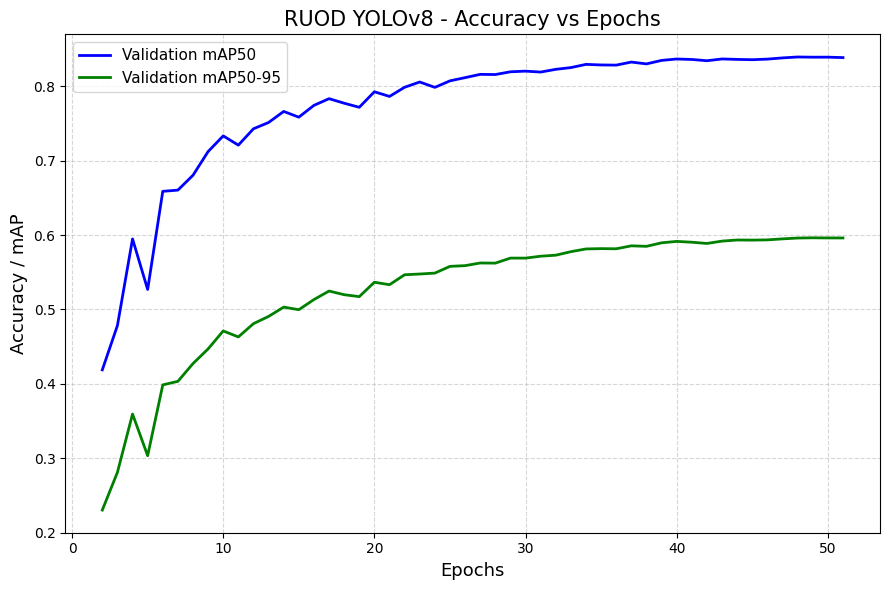

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Training results directory
RESULTS_DIR = Path(
    "/content/RUOD_results/RUOD_YOLOv8_AdamW"
)

# Read training history
df = pd.read_csv(RESULTS_DIR / "results.csv")

# Remove spaces from column names
df.columns = df.columns.str.strip()

# Epoch numbers
epochs = df["epoch"] + 1

# Plot mAP50
plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    df["metrics/mAP50(B)"],
    color="blue",
    linewidth=2,
    label="Validation mAP50"
)

plt.plot(
    epochs,
    df["metrics/mAP50-95(B)"],
    color="green",
    linewidth=2,
    label="Validation mAP50-95"
)

plt.xlabel("Epochs", fontsize=13)
plt.ylabel("Accuracy / mAP", fontsize=13)
plt.title("RUOD YOLOv8 - Accuracy vs Epochs", fontsize=15)

plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "accuracy_vs_epochs.png",
    dpi=300
)

plt.show()

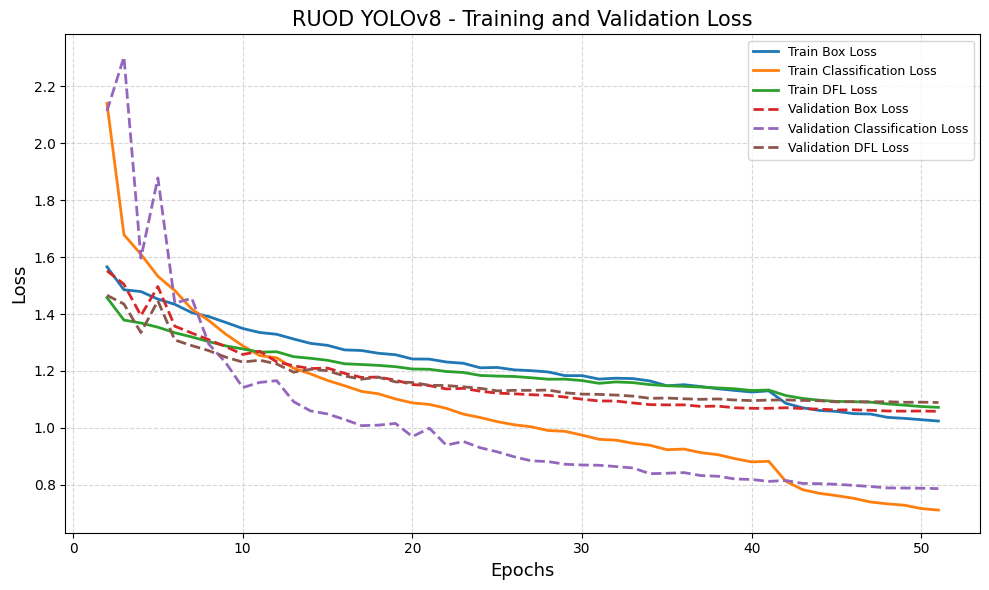

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(
    "/content/RUOD_results/RUOD_YOLOv8_AdamW"
)

df = pd.read_csv(RESULTS_DIR / "results.csv")
df.columns = df.columns.str.strip()

epochs = df["epoch"] + 1

plt.figure(figsize=(10, 6))

# Training losses
plt.plot(
    epochs,
    df["train/box_loss"],
    label="Train Box Loss",
    linewidth=2
)

plt.plot(
    epochs,
    df["train/cls_loss"],
    label="Train Classification Loss",
    linewidth=2
)

plt.plot(
    epochs,
    df["train/dfl_loss"],
    label="Train DFL Loss",
    linewidth=2
)

# Validation losses
plt.plot(
    epochs,
    df["val/box_loss"],
    linestyle="--",
    label="Validation Box Loss",
    linewidth=2
)

plt.plot(
    epochs,
    df["val/cls_loss"],
    linestyle="--",
    label="Validation Classification Loss",
    linewidth=2
)

plt.plot(
    epochs,
    df["val/dfl_loss"],
    linestyle="--",
    label="Validation DFL Loss",
    linewidth=2
)

plt.xlabel("Epochs", fontsize=13)
plt.ylabel("Loss", fontsize=13)
plt.title("RUOD YOLOv8 - Training and Validation Loss", fontsize=15)

plt.legend(fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "loss_vs_epochs.png",
    dpi=300
)

plt.show()

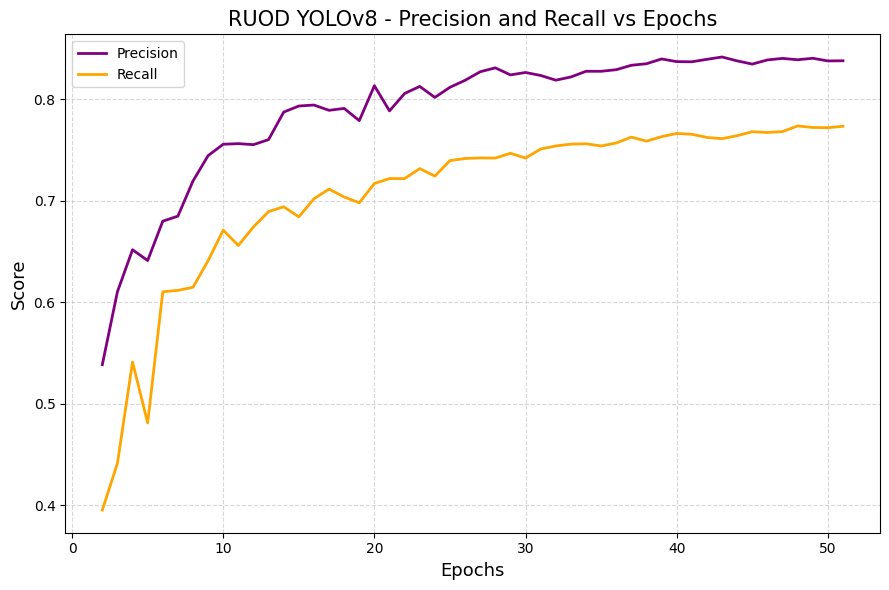

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    df["metrics/precision(B)"],
    label="Precision",
    linewidth=2,
    color="purple"
)

plt.plot(
    epochs,
    df["metrics/recall(B)"],
    label="Recall",
    linewidth=2,
    color="orange"
)

plt.xlabel("Epochs", fontsize=13)
plt.ylabel("Score", fontsize=13)
plt.title("RUOD YOLOv8 - Precision and Recall vs Epochs", fontsize=15)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "precision_recall_vs_epochs.png",
    dpi=300
)

plt.show()

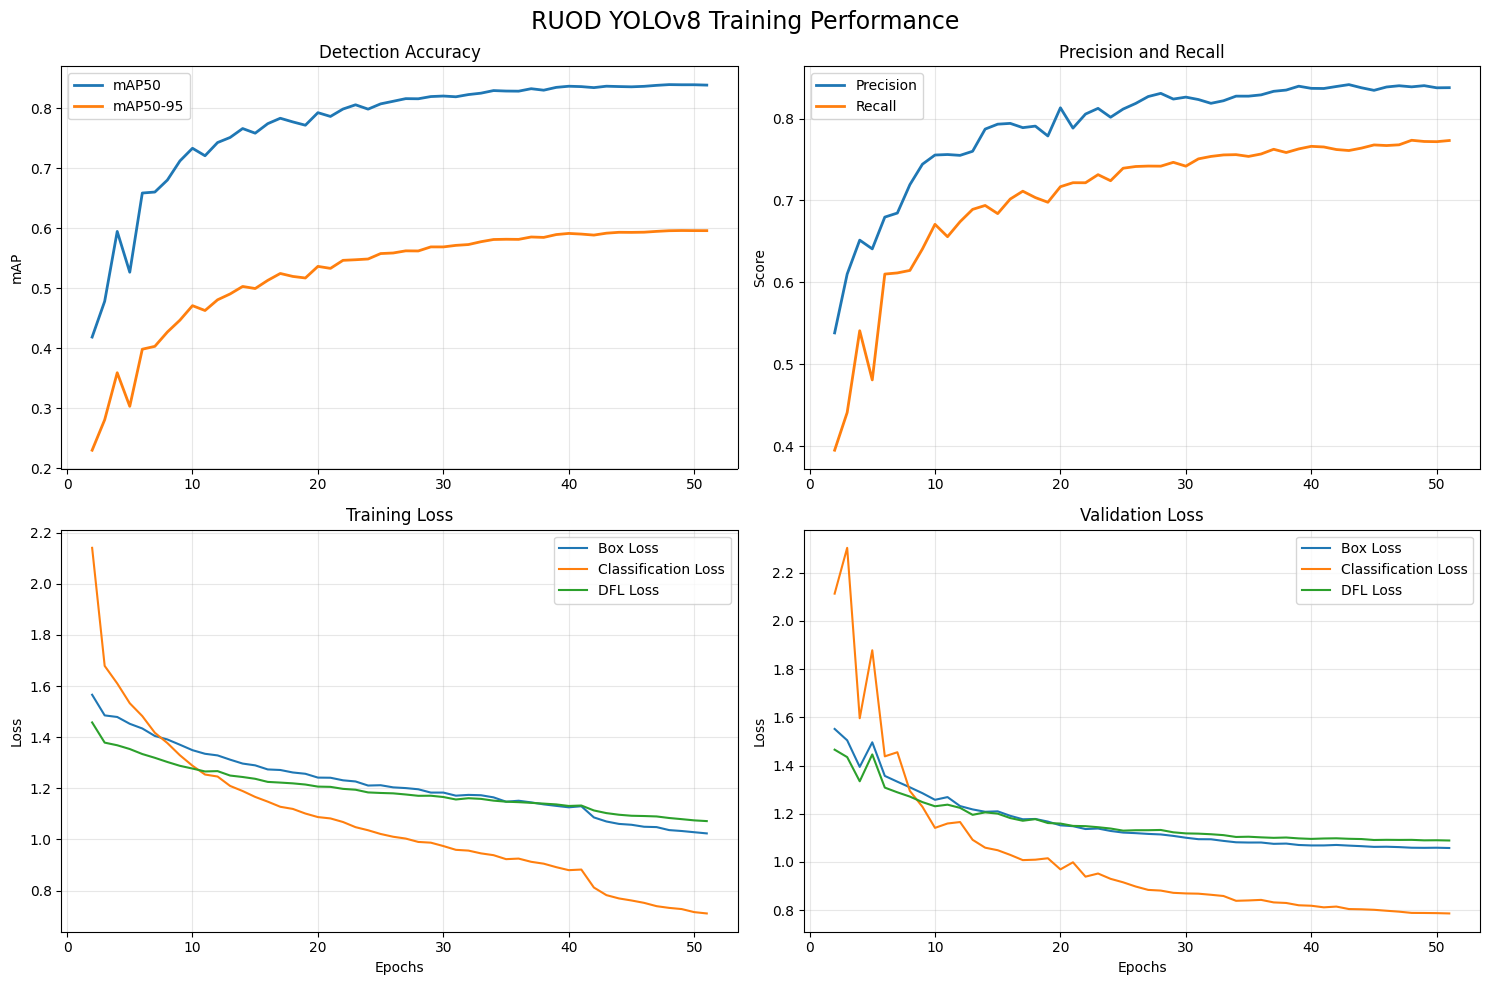

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("/content/RUOD_results/RUOD_YOLOv8_AdamW")

df = pd.read_csv(RESULTS_DIR / "results.csv")
df.columns = df.columns.str.strip()

epochs = df["epoch"] + 1

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. mAP
axes[0, 0].plot(epochs, df["metrics/mAP50(B)"],
                label="mAP50", linewidth=2)
axes[0, 0].plot(epochs, df["metrics/mAP50-95(B)"],
                label="mAP50-95", linewidth=2)
axes[0, 0].set_title("Detection Accuracy")
axes[0, 0].set_ylabel("mAP")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Precision and Recall
axes[0, 1].plot(epochs, df["metrics/precision(B)"],
                label="Precision", linewidth=2)
axes[0, 1].plot(epochs, df["metrics/recall(B)"],
                label="Recall", linewidth=2)
axes[0, 1].set_title("Precision and Recall")
axes[0, 1].set_ylabel("Score")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Training losses
axes[1, 0].plot(epochs, df["train/box_loss"],
                label="Box Loss")
axes[1, 0].plot(epochs, df["train/cls_loss"],
                label="Classification Loss")
axes[1, 0].plot(epochs, df["train/dfl_loss"],
                label="DFL Loss")
axes[1, 0].set_title("Training Loss")
axes[1, 0].set_xlabel("Epochs")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Validation losses
axes[1, 1].plot(epochs, df["val/box_loss"],
                label="Box Loss")
axes[1, 1].plot(epochs, df["val/cls_loss"],
                label="Classification Loss")
axes[1, 1].plot(epochs, df["val/dfl_loss"],
                label="DFL Loss")
axes[1, 1].set_title("Validation Loss")
axes[1, 1].set_xlabel("Epochs")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle("RUOD YOLOv8 Training Performance", fontsize=17)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "combined_training_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# **YOLO11n Performance**

In [ ]:
!pip install -U ultralytics

In [ ]:
from ultralytics import YOLO
import torch

# Check GPU
print("GPU available:", torch.cuda.is_available())

# Load pretrained YOLO11 Nano
model = YOLO("yolo11n.pt")

# Train on RUOD dataset
results = model.train(
    data="/content/RUOD_yolo/ruod.yaml",

    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,

    # Optimization
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    momentum=0.9,
    weight_decay=0.0005,
    warmup_epochs=5,

    # Training settings
    patience=20,
    cos_lr=True,
    seed=42,
    deterministic=True,

    # Data augmentation
    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=10,

    # Save results
    save=True,
    plots=True,

    project="/content/RUOD_results",
    name="RUOD_YOLO11n",
    exist_ok=True
)

print("YOLO11n training completed!")

GPU available: True
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/RUOD_yolo/ruod.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=RUOD_YOLO11n, nbs=64, nms=None, opset=None

In [ ]:
from ultralytics import YOLO

# Load best checkpoint
model = YOLO(
    "/content/RUOD_results/RUOD_YOLO11n/weights/best.pt"
)

# Validation
metrics = model.val(
    data="/content/RUOD_yolo/ruod.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0
)

print("\nYOLO11n Validation Results")
print("--------------------------")

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3662.1±1959.0 MB/s, size: 267.8 KB)
val: Scanning /content/RUOD_yolo/labels/val.cache... 4200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4200/4200 1.2Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 263/263 9.4it/s 28.1s
                   all       4200      22380      0.834      0.768      0.835      0.584
           holothurian        752       2269      0.839      0.665      0.776       0.46
               echinus        775       3306      0.868      0.827      0.883      0.504
               scallop        439       2192      0.816      0.573      0.726      0.439
              starfish        758       2336      0.829       0.82      0.875      0.523
                  fish        959     

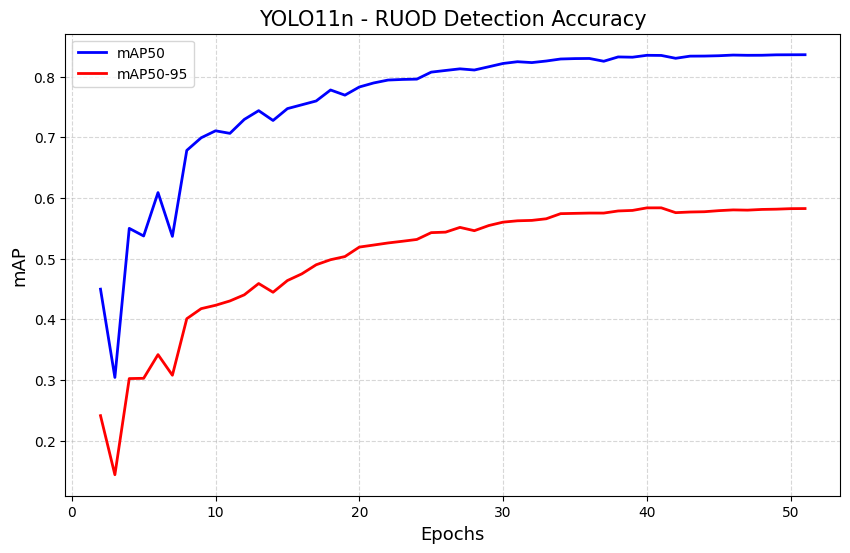

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/RUOD_results/RUOD_YOLO11n"

df = pd.read_csv(RESULTS_DIR + "/results.csv")
df.columns = df.columns.str.strip()

epochs = df["epoch"] + 1

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    df["metrics/mAP50(B)"],
    label="mAP50",
    linewidth=2,
    color="blue"
)

plt.plot(
    epochs,
    df["metrics/mAP50-95(B)"],
    label="mAP50-95",
    linewidth=2,
    color="red"
)

plt.xlabel("Epochs", fontsize=13)
plt.ylabel("mAP", fontsize=13)

plt.title("YOLO11n - RUOD Detection Accuracy", fontsize=15)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(
    RESULTS_DIR + "/accuracy_vs_epochs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

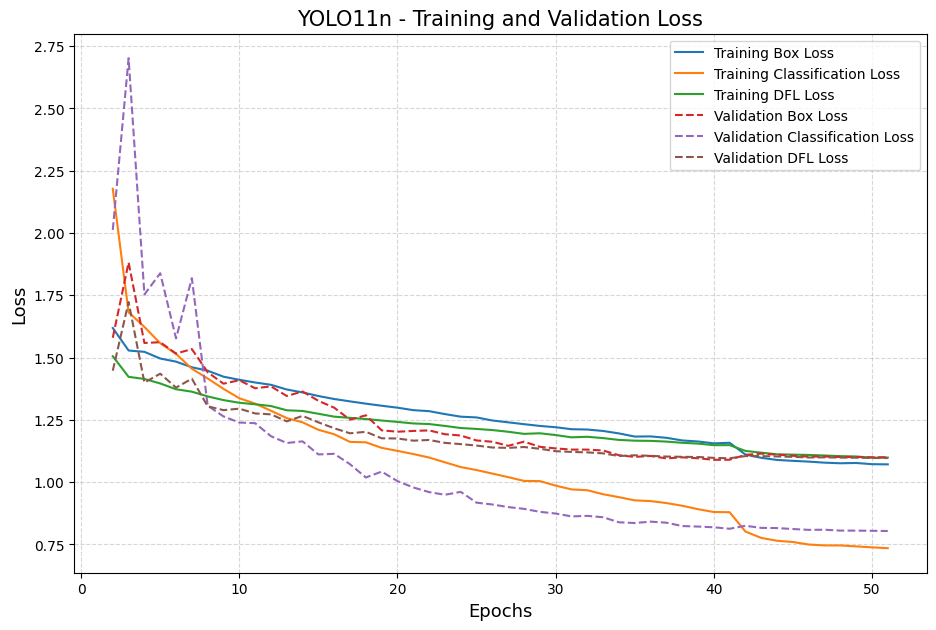

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

epochs = df["epoch"] + 1

# Training losses
plt.plot(epochs, df["train/box_loss"],
         label="Training Box Loss")

plt.plot(epochs, df["train/cls_loss"],
         label="Training Classification Loss")

plt.plot(epochs, df["train/dfl_loss"],
         label="Training DFL Loss")

# Validation losses
plt.plot(epochs, df["val/box_loss"],
         linestyle="--", label="Validation Box Loss")

plt.plot(epochs, df["val/cls_loss"],
         linestyle="--", label="Validation Classification Loss")

plt.plot(epochs, df["val/dfl_loss"],
         linestyle="--", label="Validation DFL Loss")

plt.xlabel("Epochs", fontsize=13)
plt.ylabel("Loss", fontsize=13)

plt.title("YOLO11n - Training and Validation Loss", fontsize=15)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.savefig(
    RESULTS_DIR + "/loss_vs_epochs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

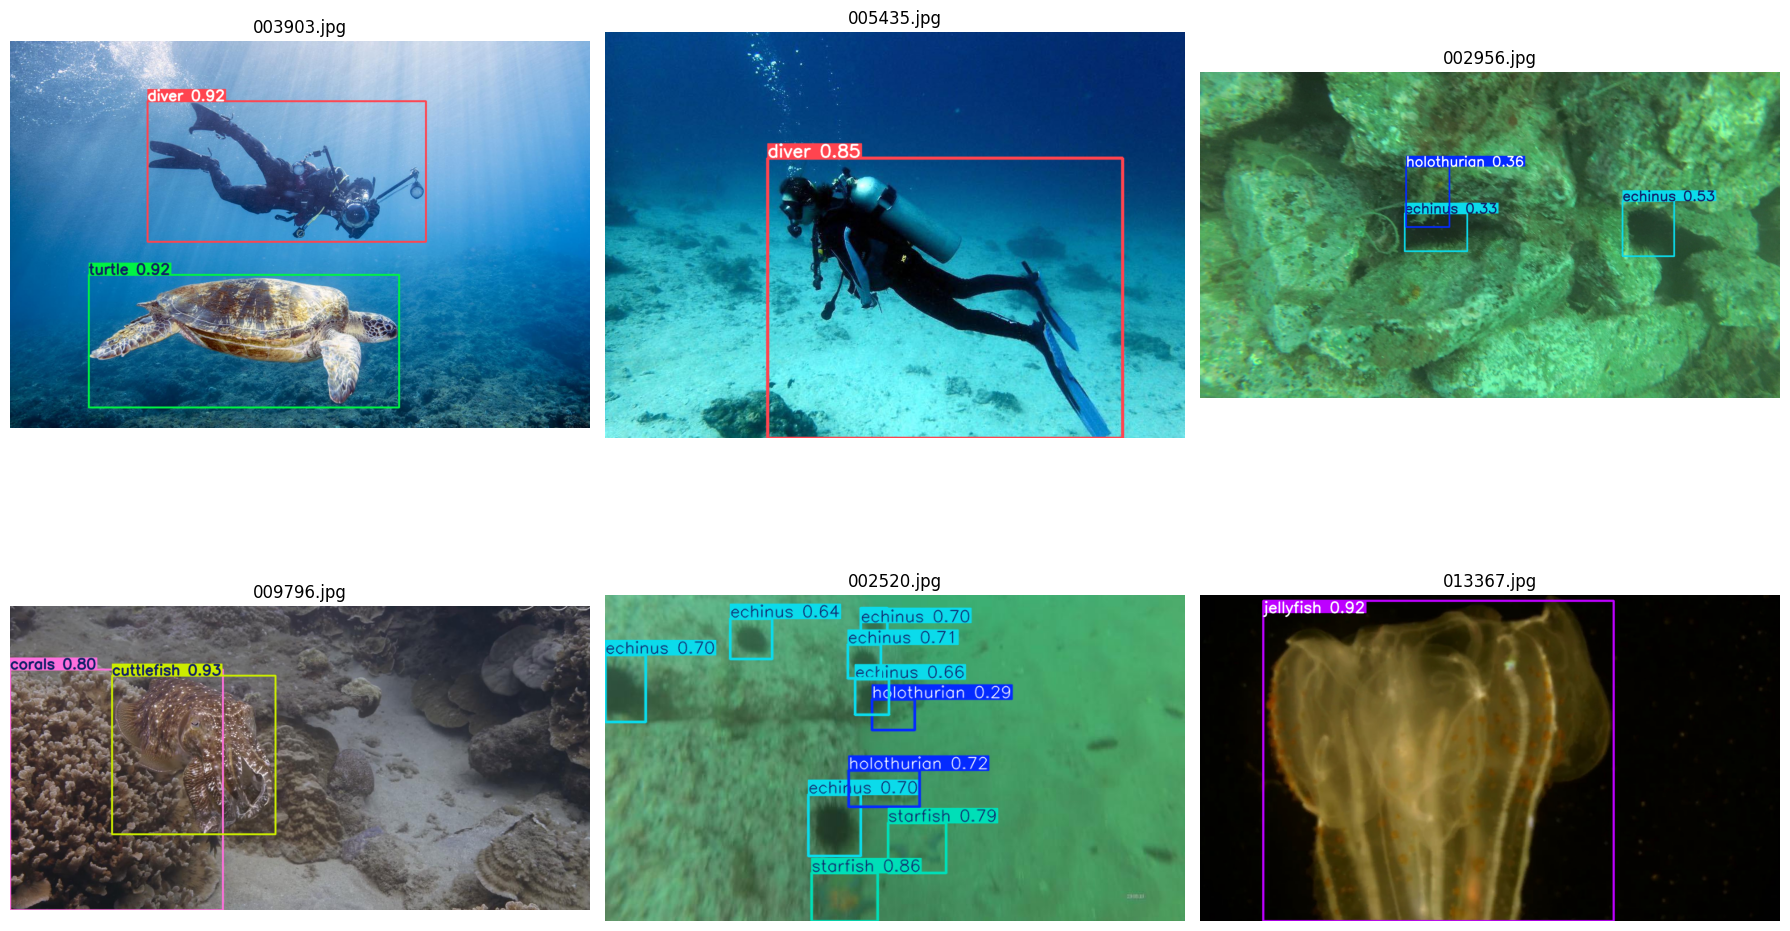

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

from pathlib import Path

VAL_DIR = Path("/content/RUOD_yolo/images/val")

image_files = list(VAL_DIR.glob("*.jpg"))

sample_images = random.sample(
    image_files,
    min(6, len(image_files))
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, img_path in enumerate(sample_images):

    result = model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    annotated = result.plot()

    annotated = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(annotated)
    axes[i].set_title(img_path.name)
    axes[i].axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

v8 = pd.read_csv(
    "/content/RUOD_results/RUOD_YOLOv8_AdamW/results.csv"
)

v11 = pd.read_csv(
    "/content/RUOD_results/RUOD_YOLO11n/results.csv"
)

v8.columns = v8.columns.str.strip()
v11.columns = v11.columns.str.strip()

comparison = pd.DataFrame({
    "Model": ["YOLOv8n", "YOLO11n"],

    "Best mAP50": [
        v8["metrics/mAP50(B)"].max(),
        v11["metrics/mAP50(B)"].max()
    ],

    "Best mAP50-95": [
        v8["metrics/mAP50-95(B)"].max(),
        v11["metrics/mAP50-95(B)"].max()
    ],

    "Best Precision": [
        v8["metrics/precision(B)"].max(),
        v11["metrics/precision(B)"].max()
    ],

    "Best Recall": [
        v8["metrics/recall(B)"].max(),
        v11["metrics/recall(B)"].max()
    ]
})

print(comparison.to_string(index=False))

  Model  Best mAP50  Best mAP50-95  Best Precision  Best Recall
YOLOv8n     0.83957        0.59637         0.84147      0.77352
YOLO11n     0.83619        0.58383         0.83753      0.77207
